In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load both datasets
apps = pd.read_csv("googleplaystore.csv")
reviews = pd.read_csv("googleplaystore_user_reviews.csv")

# Display basic information
print("Google Play Store Apps Dataset")
print("Shape:", apps.shape)
display(apps.head())

print("\nUser Reviews Dataset")
print("Shape:", reviews.shape)
display(reviews.head())


Google Play Store Apps Dataset
Shape: (10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up



User Reviews Dataset
Shape: (64295, 5)


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [2]:

# Step 2: Inspect and clean the datasets

print("APPS DATASET")
print("Shape:", apps.shape)
print("\nColumn names:")
print(apps.columns.tolist())

print("\nMissing values:")
display(apps.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", apps.duplicated().sum())

print("\nREVIEWS DATASET")
print("Shape:", reviews.shape)

print("\nMissing values:")
display(reviews.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:", reviews.duplicated().sum())

# Check data types
print("\nApps data types:")
display(apps.dtypes)

print("\nReviews data types:")
display(reviews.dtypes)


APPS DATASET
Shape: (10841, 13)

Column names:
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

Missing values:


Rating            1474
Current Ver          8
Android Ver          3
Content Rating       1
Type                 1
Size                 0
Reviews              0
Category             0
App                  0
Price                0
Installs             0
Last Updated         0
Genres               0
dtype: int64


Duplicate rows: 483

REVIEWS DATASET
Shape: (64295, 5)

Missing values:


Translated_Review         26868
Sentiment_Polarity        26863
Sentiment                 26863
Sentiment_Subjectivity    26863
App                           0
dtype: int64


Duplicate rows: 33616

Apps data types:


App                   str
Category              str
Rating            float64
Reviews               str
Size                  str
Installs              str
Type                  str
Price                 str
Content Rating        str
Genres                str
Last Updated          str
Current Ver           str
Android Ver           str
dtype: object


Reviews data types:


App                           str
Translated_Review             str
Sentiment                     str
Sentiment_Polarity        float64
Sentiment_Subjectivity    float64
dtype: object

In [3]:

# Step 3: Clean both datasets

# 1. Clean Apps Dataset
apps_clean = apps.copy()

# Remove duplicate rows
apps_clean = apps_clean.drop_duplicates()

# Convert numeric columns to numeric format
apps_clean["Rating"] = pd.to_numeric(apps_clean["Rating"], errors="coerce")
apps_clean["Reviews"] = pd.to_numeric(apps_clean["Reviews"], errors="coerce")

# Remove rows with missing essential information
apps_clean = apps_clean.dropna(
    subset=["App", "Category", "Rating", "Type", "Installs"]
)

# Clean Installs column
apps_clean["Installs"] = (
    apps_clean["Installs"]
    .str.replace("+", "", regex=False)
    .str.replace(",", "", regex=False)
)
apps_clean["Installs"] = pd.to_numeric(
    apps_clean["Installs"], errors="coerce"
)

# Clean Price column
apps_clean["Price"] = (
    apps_clean["Price"]
    .str.replace("$", "", regex=False)
)
apps_clean["Price"] = pd.to_numeric(
    apps_clean["Price"], errors="coerce"
)

# Remove rows where conversion failed
apps_clean = apps_clean.dropna(
    subset=["Reviews", "Installs", "Price"]
)

# 2. Clean User Reviews Dataset
reviews_clean = reviews.copy()

# Remove rows without review text or sentiment
reviews_clean = reviews_clean.dropna(
    subset=["Translated_Review", "Sentiment"]
)

# Remove exact duplicate rows
reviews_clean = reviews_clean.drop_duplicates()

# Display results
print("Apps dataset before cleaning:", apps.shape)
print("Apps dataset after cleaning:", apps_clean.shape)

print("\nReviews dataset before cleaning:", reviews.shape)
print("Reviews dataset after cleaning:", reviews_clean.shape)

print("\nMissing values in cleaned Apps:")
display(apps_clean.isnull().sum())

print("\nMissing values in cleaned Reviews:")
display(reviews_clean.isnull().sum())

print("\nApps data types after cleaning:")
display(apps_clean[["Rating", "Reviews", "Installs", "Price"]].dtypes)


Apps dataset before cleaning: (10841, 13)
Apps dataset after cleaning: (8892, 13)

Reviews dataset before cleaning: (64295, 5)
Reviews dataset after cleaning: (29692, 5)

Missing values in cleaned Apps:


App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       4
Android Ver       2
dtype: int64


Missing values in cleaned Reviews:


App                       0
Translated_Review         0
Sentiment                 0
Sentiment_Polarity        0
Sentiment_Subjectivity    0
dtype: int64


Apps data types after cleaning:


Rating      float64
Reviews     float64
Installs    float64
Price       float64
dtype: object

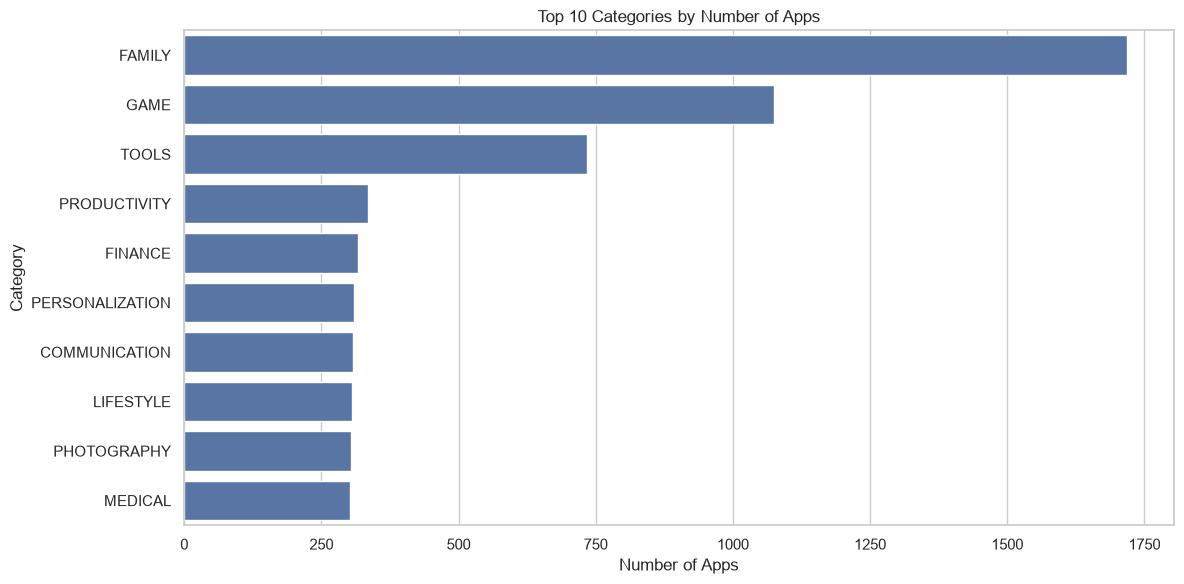

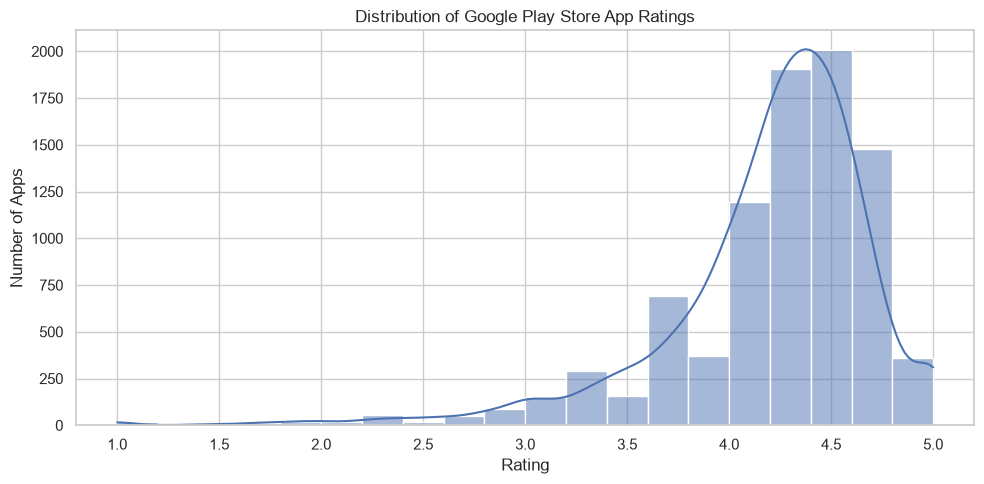

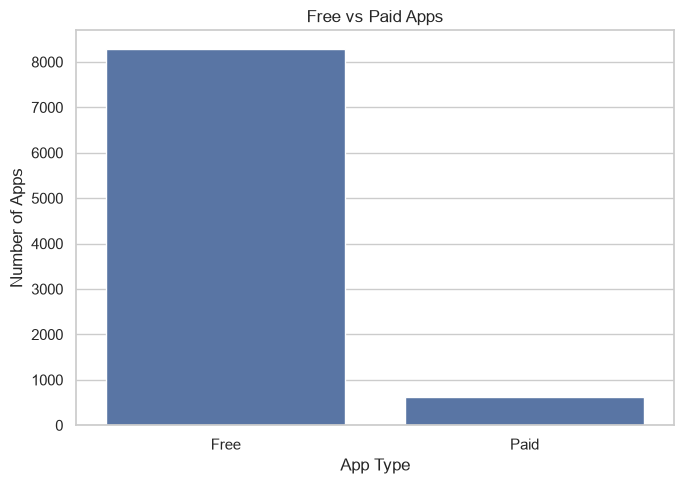

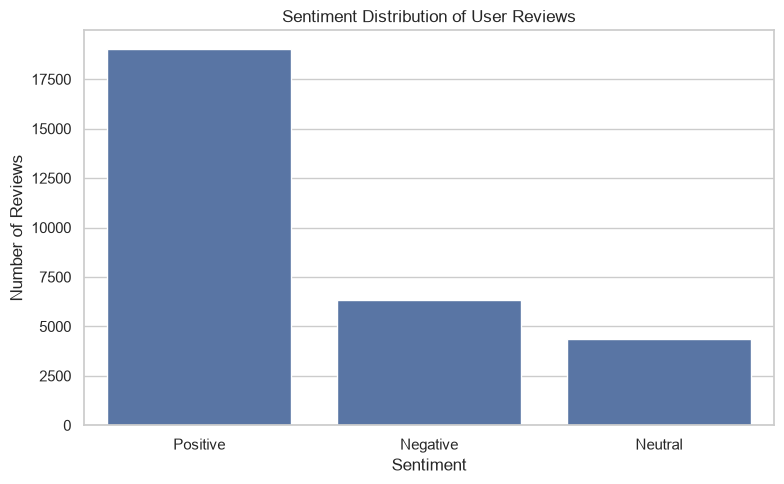

In [4]:

# Step 4: Exploratory Data Analysis (EDA)

sns.set_theme(style="whitegrid")

# Graph 1: Top 10 Categories by Number of Apps
plt.figure(figsize=(12, 6))
top_categories = apps_clean["Category"].value_counts().head(10)

sns.barplot(
    x=top_categories.values,
    y=top_categories.index
)
plt.title("Top 10 Categories by Number of Apps")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.tight_layout()
plt.show()


# Graph 2: Distribution of App Ratings
plt.figure(figsize=(10, 5))
sns.histplot(
    apps_clean["Rating"],
    bins=20,
    kde=True
)
plt.title("Distribution of Google Play Store App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()


# Graph 3: Free vs Paid Apps
plt.figure(figsize=(7, 5))
type_counts = apps_clean["Type"].value_counts()

sns.barplot(
    x=type_counts.index,
    y=type_counts.values
)
plt.title("Free vs Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Number of Apps")
plt.tight_layout()
plt.show()


# Graph 4: Sentiment Distribution in User Reviews
plt.figure(figsize=(8, 5))
sentiment_counts = reviews_clean["Sentiment"].value_counts()

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)
plt.title("Sentiment Distribution of User Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


Top 10 Most Installed Apps:


,App,Category,Installs,Rating
3896,Subway Surfers,GAME,1.000000e+09,4.5
4153,Hangouts,COMMUNICATION,1.000000e+09,4.0
4150,Google,TOOLS,1.000000e+09,4.4
3904,WhatsApp Messenger,COMMUNICATION,1.000000e+09,4.4
3816,Google News,NEWS_AND_MAGAZINES,1.000000e+09,3.9
3127,Google Street View,TRAVEL_AND_LOCAL,1.000000e+09,4.2
3909,Instagram,SOCIAL,1.000000e+09,4.5
1654,Subway Surfers,GAME,1.000000e+09,4.5
4144,Google+,SOCIAL,1.000000e+09,4.2
3523,Google Drive,PRODUCTIVITY,1.000000e+09,4.4



Average Rating: Free vs Paid Apps


,Type,Rating
0,Free,4.18
1,Paid,4.26



Average Installs: Free vs Paid Apps


,Type,Installs
0,Free,17702227.0
1,Paid,112908.0


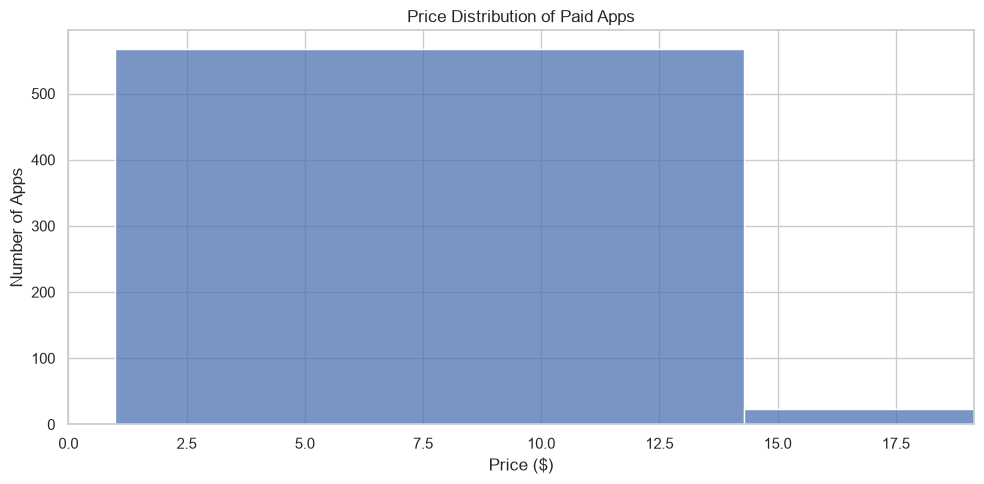


Top 10 Categories by Average Rating:


,Category,Rating
0,EVENTS,4.44
1,EDUCATION,4.38
2,ART_AND_DESIGN,4.36
3,BOOKS_AND_REFERENCE,4.35
4,PERSONALIZATION,4.33
5,PARENTING,4.30
6,GAME,4.28
7,BEAUTY,4.28
8,HEALTH_AND_FITNESS,4.26
9,SOCIAL,4.25


In [5]:

# Step 5: Analyze installs, price and ratings

# 1. Top 10 most-installed apps
top_installed = apps_clean.sort_values(
    by="Installs", ascending=False
).head(10)

print("Top 10 Most Installed Apps:")
display(top_installed[["App", "Category", "Installs", "Rating"]])


# 2. Average rating by app type
print("\nAverage Rating: Free vs Paid Apps")
display(
    apps_clean.groupby("Type")["Rating"]
    .mean()
    .round(2)
    .reset_index()
)


# 3. Average installs by app type
print("\nAverage Installs: Free vs Paid Apps")
display(
    apps_clean.groupby("Type")["Installs"]
    .mean()
    .round(0)
    .reset_index()
)


# 4. Price distribution for paid apps
paid_apps = apps_clean[
    (apps_clean["Type"] == "Paid") &
    (apps_clean["Price"] > 0)
]

plt.figure(figsize=(10, 5))
sns.histplot(paid_apps["Price"], bins=30)
plt.title("Price Distribution of Paid Apps")
plt.xlabel("Price ($)")
plt.ylabel("Number of Apps")
plt.xlim(0, paid_apps["Price"].quantile(0.95))
plt.tight_layout()
plt.show()


# 5. Average rating by category
category_ratings = (
    apps_clean.groupby("Category")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

print("\nTop 10 Categories by Average Rating:")
display(category_ratings.head(10).round(2).reset_index())


Sentiment Counts:


,Sentiment,count
0,Positive,19015
1,Negative,6321
2,Neutral,4356



Sentiment Percentage:


,Sentiment,proportion
0,Positive,64.04
1,Negative,21.29
2,Neutral,14.67


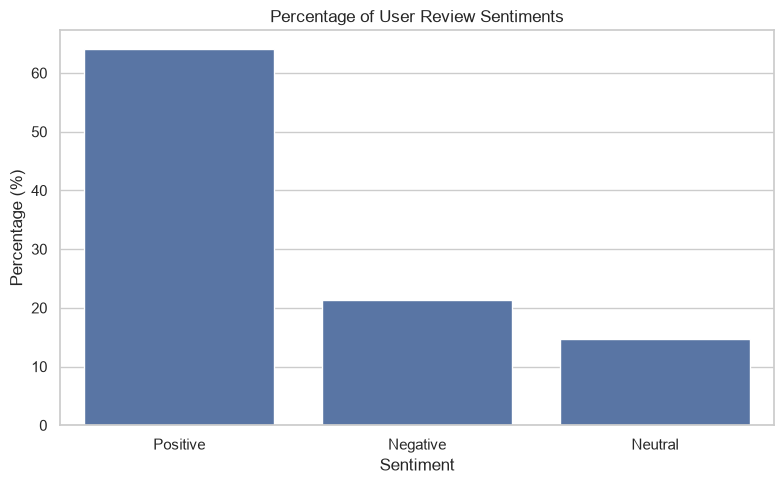

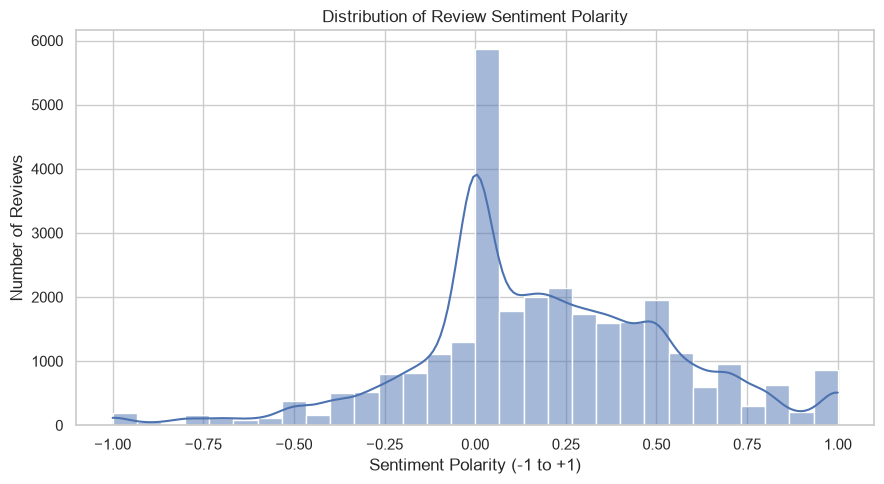


Sentiment Polarity Summary:


count    29692.000
mean         0.189
std          0.356
min         -1.000
25%          0.000
50%          0.157
75%          0.423
max          1.000
Name: Sentiment_Polarity, dtype: float64

In [6]:

# Step 6: User Reviews Sentiment Analysis

# Sentiment counts
sentiment_counts = reviews_clean["Sentiment"].value_counts()

print("Sentiment Counts:")
display(sentiment_counts.reset_index())

# Sentiment percentages
sentiment_percent = (
    reviews_clean["Sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nSentiment Percentage:")
display(sentiment_percent.reset_index())


# Graph 1: Sentiment percentages
plt.figure(figsize=(8, 5))
sns.barplot(
    x=sentiment_percent.index,
    y=sentiment_percent.values
)
plt.title("Percentage of User Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Percentage (%)")
plt.tight_layout()
plt.show()


# Graph 2: Sentiment polarity distribution
plt.figure(figsize=(9, 5))
sns.histplot(
    data=reviews_clean,
    x="Sentiment_Polarity",
    bins=30,
    kde=True
)
plt.title("Distribution of Review Sentiment Polarity")
plt.xlabel("Sentiment Polarity (-1 to +1)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


# Summary statistics
print("\nSentiment Polarity Summary:")
display(reviews_clean["Sentiment_Polarity"].describe().round(3))


In [7]:

# Step 7: Final Project Insights

print("=" * 55)
print("GOOGLE PLAY STORE ANALYSIS - KEY FINDINGS")
print("=" * 55)

print(f"\nOriginal apps dataset: {len(apps):,} rows")
print(f"Cleaned apps dataset: {len(apps_clean):,} rows")
print(f"Original reviews dataset: {len(reviews):,} rows")
print(f"Cleaned reviews dataset: {len(reviews_clean):,} rows")

print("\n1. TOP APP CATEGORIES")
display(apps_clean["Category"].value_counts().head(5).rename("App Count"))

print("\n2. AVERAGE APP RATING")
print(round(apps_clean["Rating"].mean(), 2))

print("\n3. FREE VS PAID APPS")
display(apps_clean["Type"].value_counts())

print("\n4. MOST POPULAR APPS BY INSTALLS")
display(
    apps_clean.nlargest(5, "Installs")[["App", "Category", "Installs", "Rating"]]
)

print("\n5. REVIEW SENTIMENT DISTRIBUTION (%)")
display(
    reviews_clean["Sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .rename("Percentage")
)

print("\n6. AVERAGE SENTIMENT POLARITY")
print(round(reviews_clean["Sentiment_Polarity"].mean(), 3))

print("\n7. AVERAGE RATING BY APP TYPE")
display(
    apps_clean.groupby("Type")["Rating"]
    .mean()
    .round(2)
)

print("\nAnalysis completed successfully!")


GOOGLE PLAY STORE ANALYSIS - KEY FINDINGS

Original apps dataset: 10,841 rows
Cleaned apps dataset: 8,892 rows
Original reviews dataset: 64,295 rows
Cleaned reviews dataset: 29,692 rows

1. TOP APP CATEGORIES


Category
FAMILY          1718
GAME            1074
TOOLS            734
PRODUCTIVITY     334
FINANCE          317
Name: App Count, dtype: int64


2. AVERAGE APP RATING
4.19

3. FREE VS PAID APPS


Type
Free    8279
Paid     613
Name: count, dtype: int64


4. MOST POPULAR APPS BY INSTALLS


...


5. REVIEW SENTIMENT DISTRIBUTION (%)


Sentiment
Positive    64.04
Negative    21.29
Neutral     14.67
Name: Percentage, dtype: float64


6. AVERAGE SENTIMENT POLARITY
0.189

7. AVERAGE RATING BY APP TYPE


Type
Free    4.18
Paid    4.26
Name: Rating, dtype: float64


Analysis completed successfully!
